<a href="https://colab.research.google.com/github/rashidsohaib10232/ml-handson-geron/blob/main/transformation_on_titanic_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import pandas as pd

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import FunctionTransformer

In [32]:
df = pd.read_csv('11 titanic.csv', usecols = ['Age','Fare','Survived'])

df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [33]:

df['Age'] = df['Age'].fillna(df['Age'].mean())

In [34]:
df['Fare'] = df['Fare'].fillna(df['Fare'].mean())

In [35]:
df.isnull().sum()

,0
Survived,0
Age,0
Fare,0


In [36]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

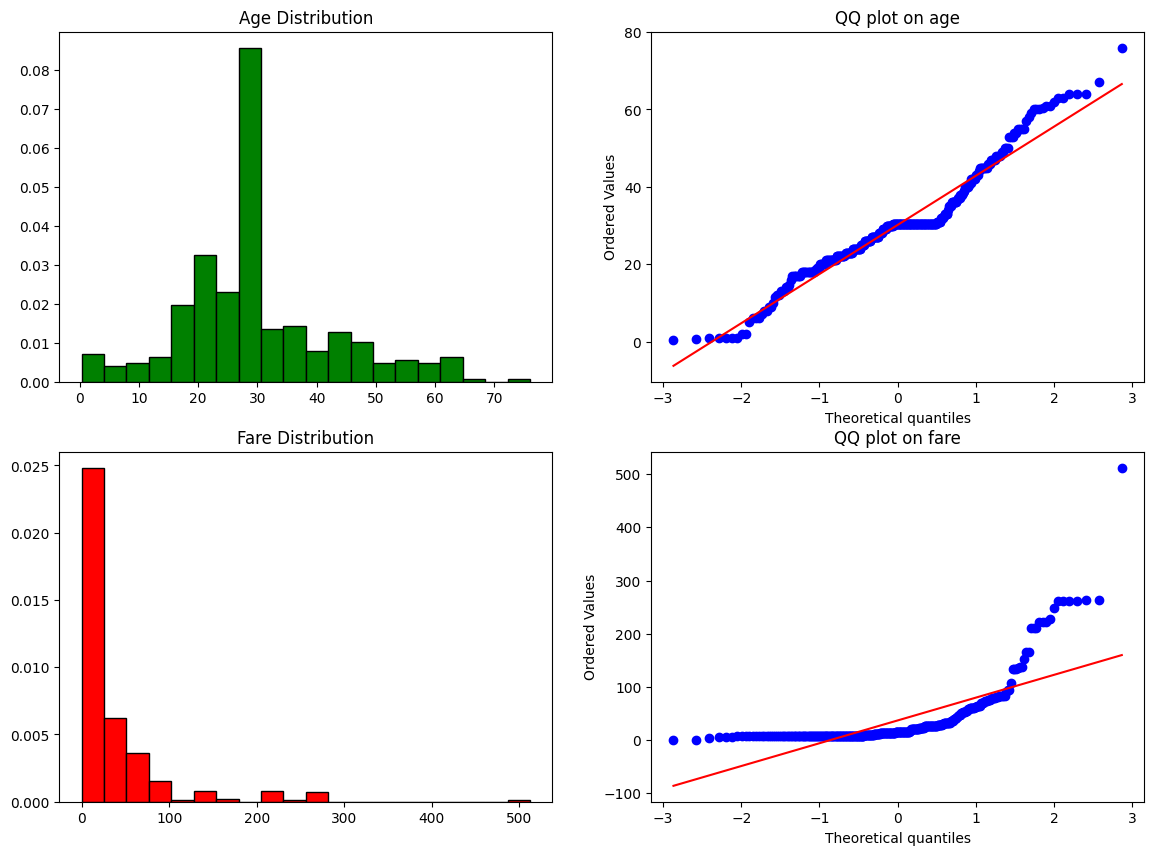

In [38]:
# create subplot with 2 rows and 2 columns
fig, axs = plt.subplots(2,2, figsize=(14,10))

# plot the first distribution plot for age
axs[0,0].hist(X_train['Age'], bins =20,density=True,alpha=1, color ='g', edgecolor = 'black' )
axs[0,0].set_title('Age Distribution')

# plot the first QQ plot for age
stats.probplot(X_train['Age'], dist='norm', plot=axs[0,1
                                                     ])
axs[0,1].set_title("QQ plot on age")
# plot fare distribution
axs[1,0].hist(X_train['Fare'], bins =20, density= True, alpha =1, color ='r', edgecolor = 'black')
axs[1,0].set_title("Fare Distribution")

# plot the second QQ plot on fare
stats.probplot(X_train['Fare'], dist='norm', plot=axs[1,1])
axs[1,1].set_title("QQ plot on fare")


plt.show()

# Training the model before the function transformation

In [39]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print("LR", accuracy_score(y_test, y_pred))
print("DT", accuracy_score(y_test, y_pred2))

LR 0.6071428571428571
DT 0.5595238095238095


# Log Transformer

In [40]:
trf = FunctionTransformer(func=np.log1p)
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)
# print(X_train_transformed)
# print(X_train)

# Again training the model

In [41]:
clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print("LR", accuracy_score(y_test, y_pred))
print("DT", accuracy_score(y_test, y_pred2))

LR 0.6190476190476191
DT 0.5476190476190477


# Reciprocal Transformer

In [42]:
# defining the reciprocal transformer

def reciprocal_transform(X):
  X=X+1e-6

  return 1/X

In [43]:
# create the Functiontransformer

trf = FunctionTransformer(func= reciprocal_transform)

# apply the transfrom to the training and testing data
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

# fitting the classifiers

clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

# making predictions

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print("LR", accuracy_score(y_test, y_pred))
print("DT", accuracy_score(y_test, y_pred2))

LR 0.6071428571428571
DT 0.5476190476190477


# plot for reciprocal

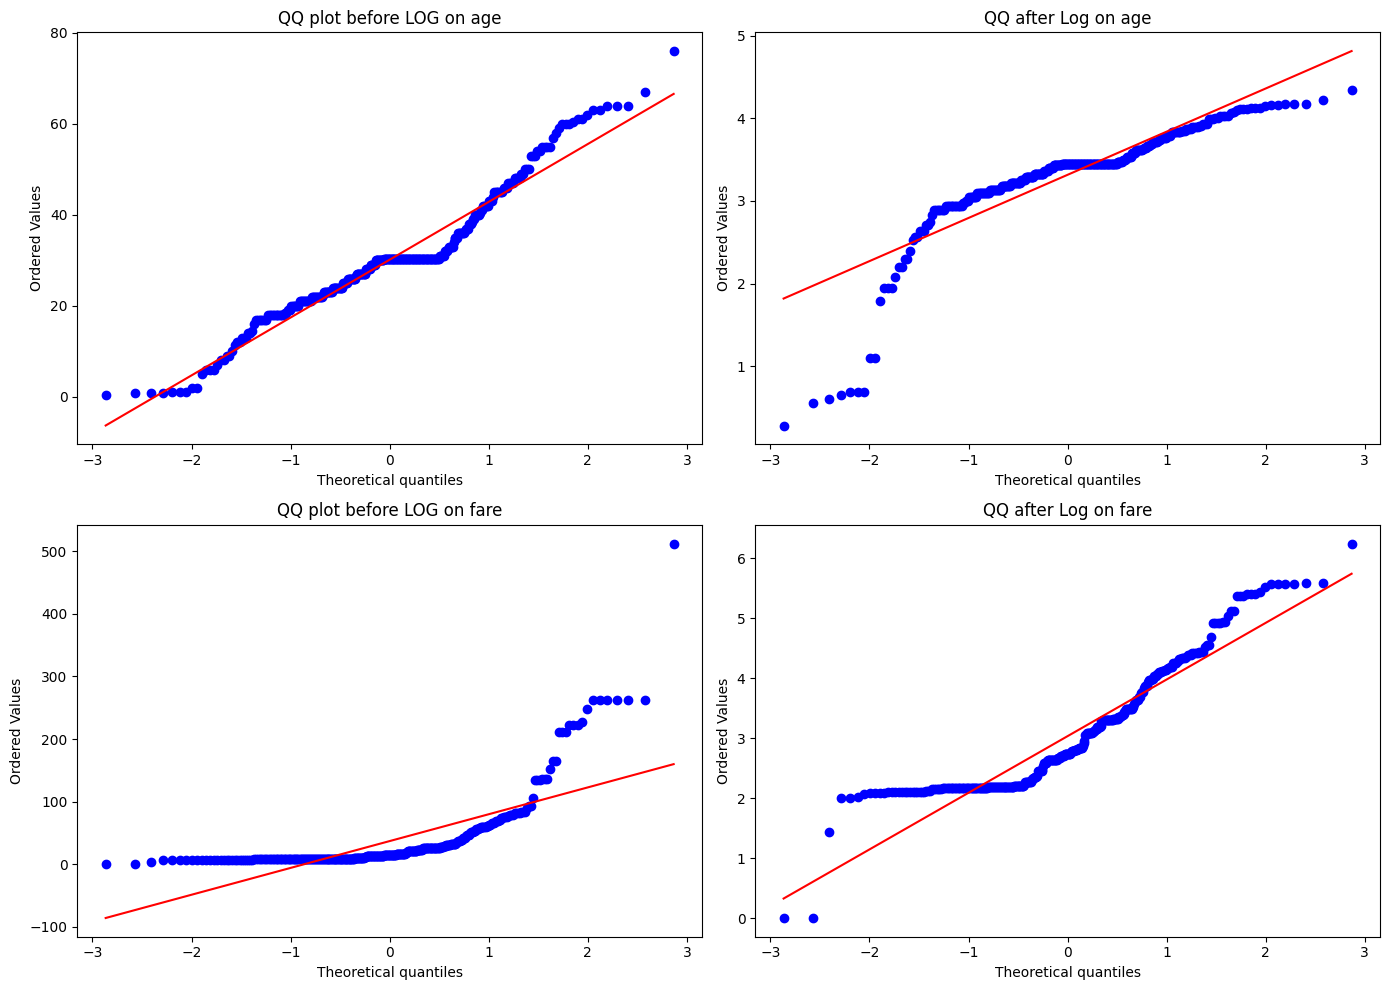

In [44]:
# First, let's regenerate the LOG transformed data so we can plot it correctly
trf_log = FunctionTransformer(func=np.log1p)
X_train_log = trf_log.fit_transform(X_train)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# plotting QQ plot for age
stats.probplot(X_train["Age"], dist='norm', plot=axs[0, 0])
axs[0, 0].set_title("QQ plot before LOG on age")

# QQ plot after Log
stats.probplot(X_train_log["Age"], dist='norm', plot=axs[0, 1])
axs[0, 1].set_title("QQ after Log on age")

# plotting QQ plot for fare
stats.probplot(X_train["Fare"], dist='norm', plot=axs[1, 0])
axs[1, 0].set_title("QQ plot before LOG on fare")

# QQ plot after Log
stats.probplot(X_train_log["Fare"], dist='norm', plot=axs[1, 1])
axs[1, 1].set_title("QQ after Log on fare")

plt.tight_layout()
plt.show()

# Plotting on Reciprocal Transformer


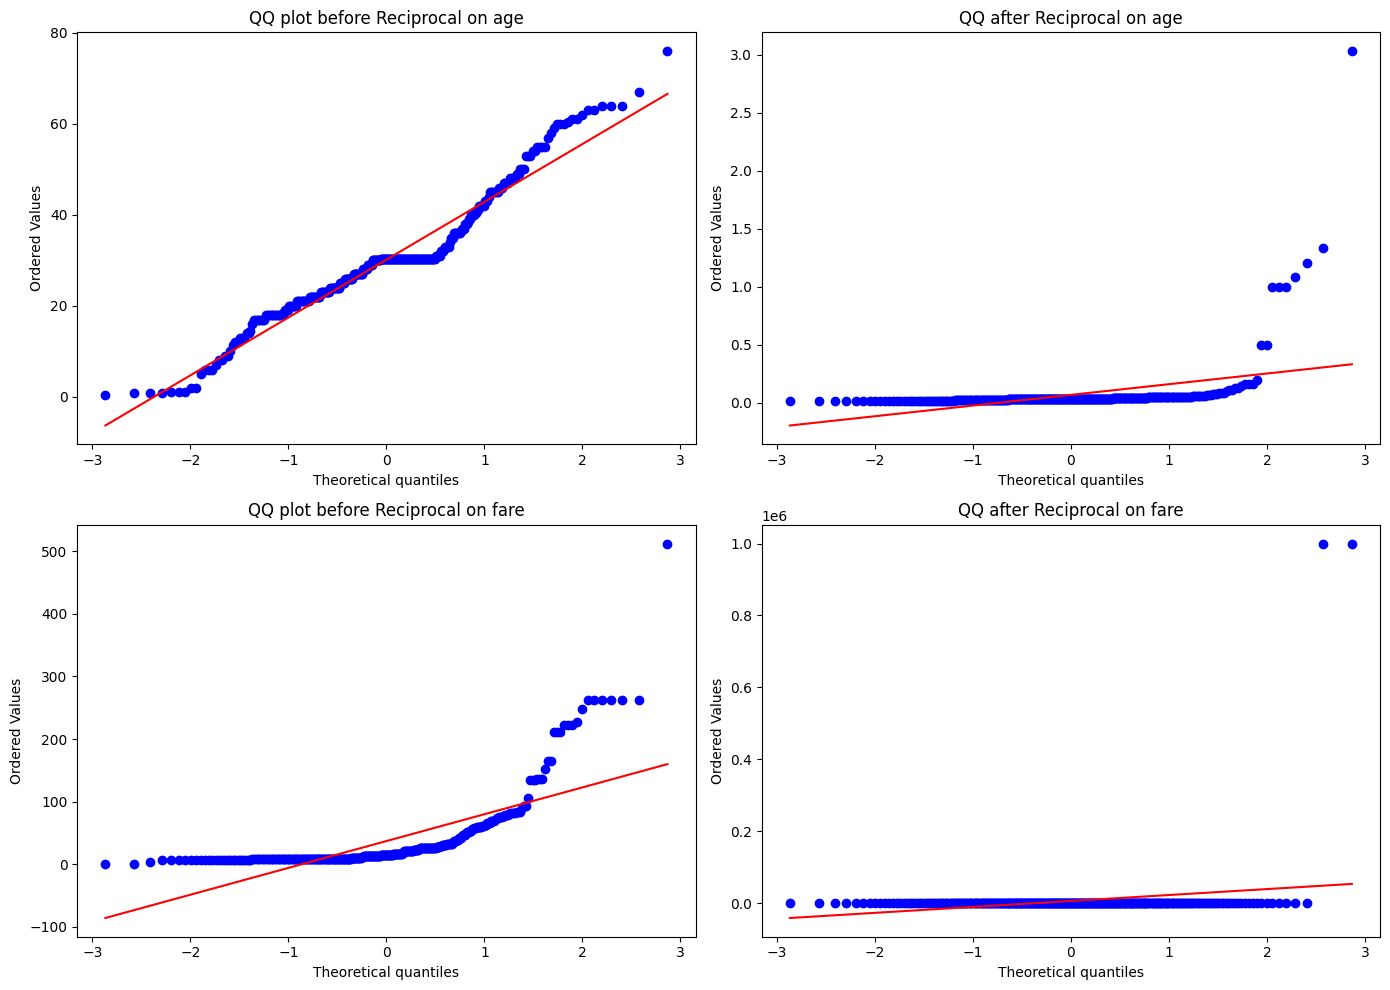

In [45]:
# Regenerate the reciprocal transformed data to make sure we have the correct variables
trf_reciprocal = FunctionTransformer(func=reciprocal_transform)
X_train_reciprocal = trf_reciprocal.fit_transform(X_train)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# plotting QQ plot for age
stats.probplot(X_train["Age"], dist='norm', plot=axs[0, 0])
axs[0, 0].set_title("QQ plot before Reciprocal on age")

# QQ plot after Reciprocal
stats.probplot(X_train_reciprocal["Age"], dist='norm', plot=axs[0, 1])
axs[0, 1].set_title("QQ after Reciprocal on age")

# plotting QQ plot for fare
stats.probplot(X_train["Fare"], dist='norm', plot=axs[1, 0])
axs[1, 0].set_title("QQ plot before Reciprocal on fare")

# QQ plot after Reciprocal
stats.probplot(X_train_reciprocal["Fare"], dist='norm', plot=axs[1, 1])
axs[1, 1].set_title("QQ after Reciprocal on fare")

plt.tight_layout()
plt.show()

# Square Transformer

In [46]:
# defining the square transformer
def square_transform(X):
  return X**2

# creating the function transformer
trf_square = FunctionTransformer(func=square_transform)

# apply the transformation to the 'fare' feature in the training and test data
X_train_transformed_fare = X_train[['Fare']].values
X_test_transformed_fare = X_test[['Fare']].values
X_train_transformed_fare = trf_square.fit_transform(X_train_transformed_fare)
X_test_transformed_fare = trf_square.transform(X_test_transformed_fare)

clf.fit(X_train_transformed_fare, y_train)
clf2.fit(X_train_transformed_fare, y_train)

y_pred = clf.predict(X_test_transformed_fare)
y_pred2 = clf2.predict(X_test_transformed_fare)

print("LR", accuracy_score(y_test, y_pred))
print("DT", accuracy_score(y_test, y_pred2))

LR 0.6071428571428571
DT 0.6071428571428571


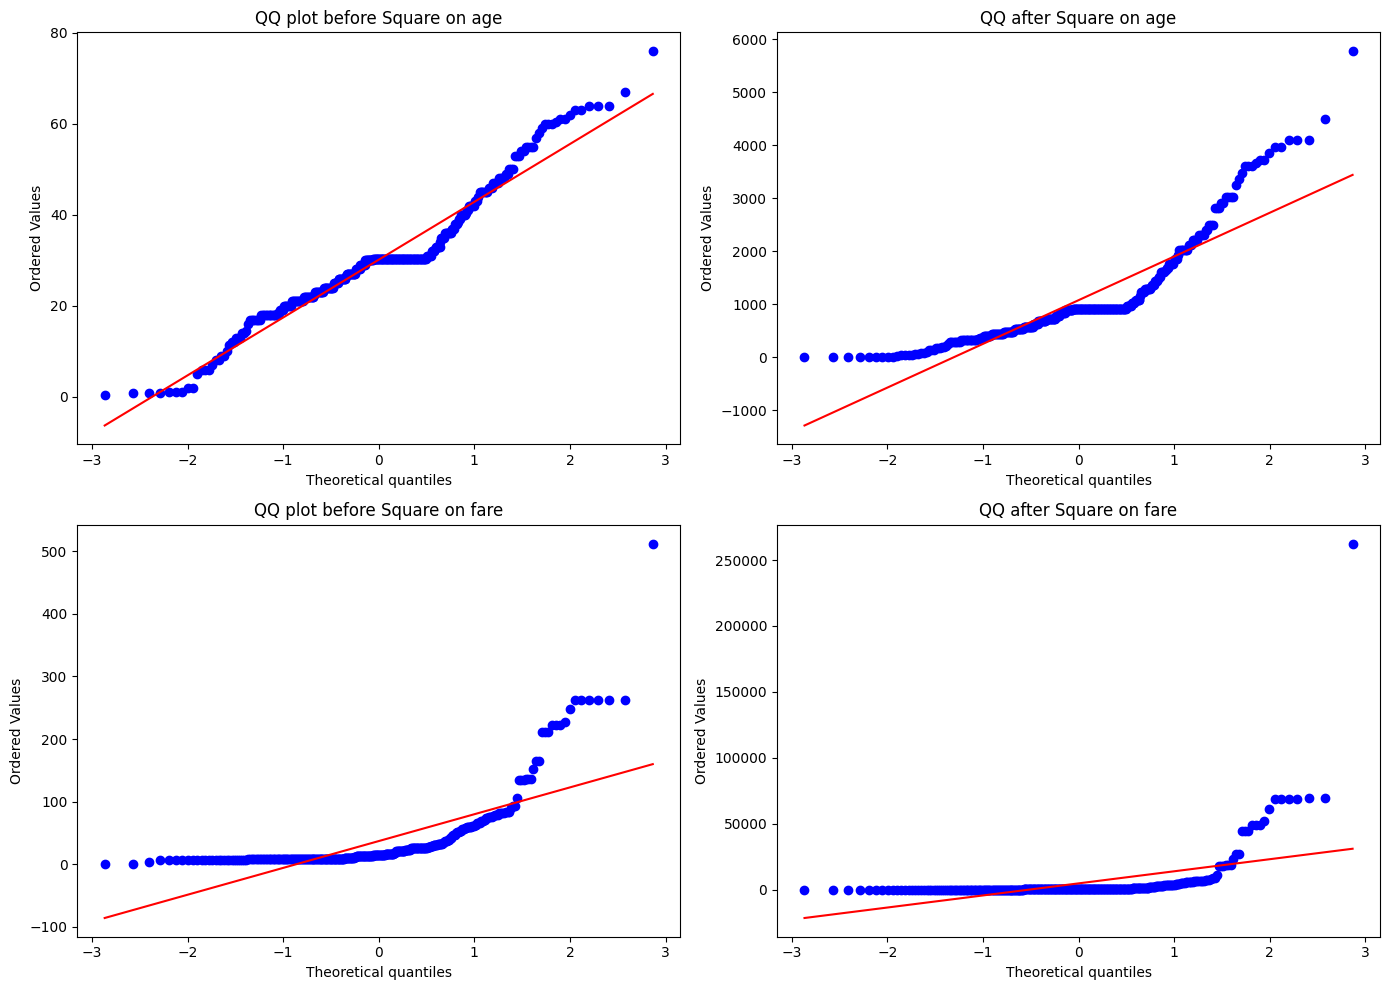

In [47]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plotting QQ plot for age before and after square transformation
stats.probplot(X_train['Age'], dist='norm', plot=axs[0, 0])
axs[0, 0].set_title("QQ plot before Square on age")

# Square transform for visualization purposes
stats.probplot(X_train['Age']**2, dist='norm', plot=axs[0, 1])
axs[0, 1].set_title("QQ after Square on age")

# Plotting QQ plot for fare before and after square transformation
stats.probplot(X_train['Fare'], dist='norm', plot=axs[1, 0])
axs[1, 0].set_title("QQ plot before Square on fare")

stats.probplot(X_train['Fare']**2, dist='norm', plot=axs[1, 1])
axs[1, 1].set_title("QQ after Square on fare")

plt.tight_layout()
plt.show()

# Square Root Transformer

In [48]:
def square_root_transform(X):
  return np.sqrt(X)

trf_sqrt = FunctionTransformer(func=square_root_transform)

X_train_transformed_fare = X_train[['Fare']].values
X_test_transformed_fare = X_test[['Fare']].values

X_train_transformed_fare = trf_sqrt.fit_transform(X_train_transformed_fare)
X_test_transformed_fare = trf_sqrt.transform(X_test_transformed_fare)

clf.fit(X_train_transformed_fare, y_train)
clf2.fit(X_train_transformed_fare, y_train)

y_pred = clf.predict(X_test_transformed_fare)
y_pred2 = clf2.predict(X_test_transformed_fare)

print("LR", accuracy_score(y_test, y_pred))
print("DT", accuracy_score(y_test, y_pred2))


LR 0.6190476190476191
DT 0.6071428571428571


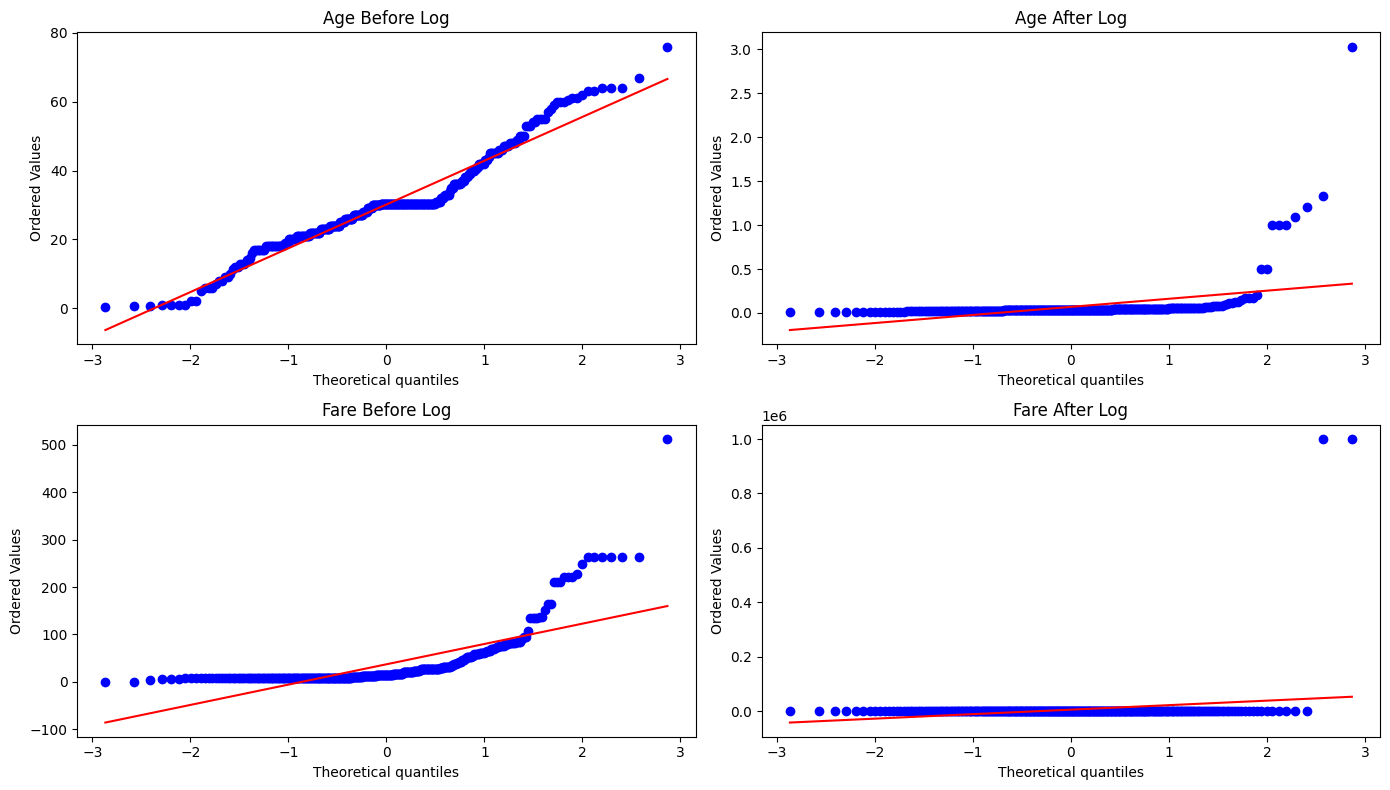

In [49]:
# Create subplots with 2 rows and 2 columns
fig, axs = plt.subplots(2, 2, figsize=(14, 8))

# Plot the first QQ plot for Age Before Log
stats.probplot(X_train['Age'], dist="norm", plot=axs[0, 0])
axs[0, 0].set_title('Age Before Log')

# Plot the second QQ plot for Age After Log
stats.probplot(X_train_transformed['Age'], dist="norm", plot=axs[0, 1])
axs[0, 1].set_title('Age After Log')

# Plot the third QQ plot for Fare Before Log
stats.probplot(X_train['Fare'], dist="norm", plot=axs[1, 0])
axs[1, 0].set_title('Fare Before Log')

# Plot the fourth QQ plot for Fare After Log
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=axs[1, 1])
axs[1, 1].set_title('Fare After Log')

plt.tight_layout()  # Adjust layout to prevent overlapping
plt.show()
